<a href="https://colab.research.google.com/github/andyotani/PCVK_Ganjil_26-27/blob/main/Jobsheet07/JS07_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Praktikum Segmentasi Citra dengan Thresholding

Tugas Individu

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

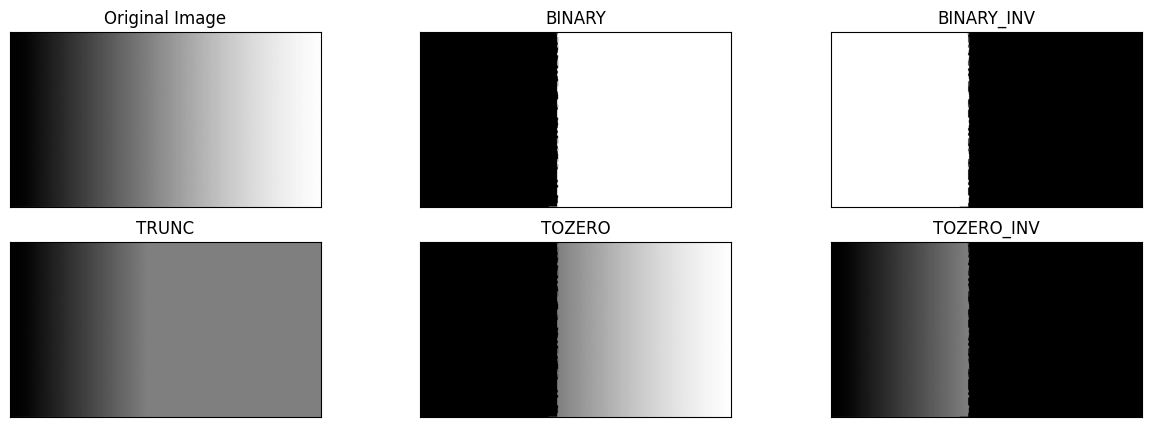

In [4]:
# Membuat Global Threshold
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')

img = cv.imread(filename)

thresh = 127
maxval = 255


# 1. Binary Threshold
ret, thresh1 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_BINARY
)


# 2. Binary Inverse Threshold
ret, thresh2 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_BINARY_INV
)


# 3. Truncate Threshold
ret, thresh3 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TRUNC
)


# 4. Threshold To Zero
ret, thresh4 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TOZERO
)


# 5. Threshold To Zero Inverse
ret, thresh5 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TOZERO_INV
)


titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]


images = [
    img,
    thresh1,
    thresh2,
    thresh3,
    thresh4,
    thresh5
]


plt.figure(figsize=(15,5))

for i in range(len(images)):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i],'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

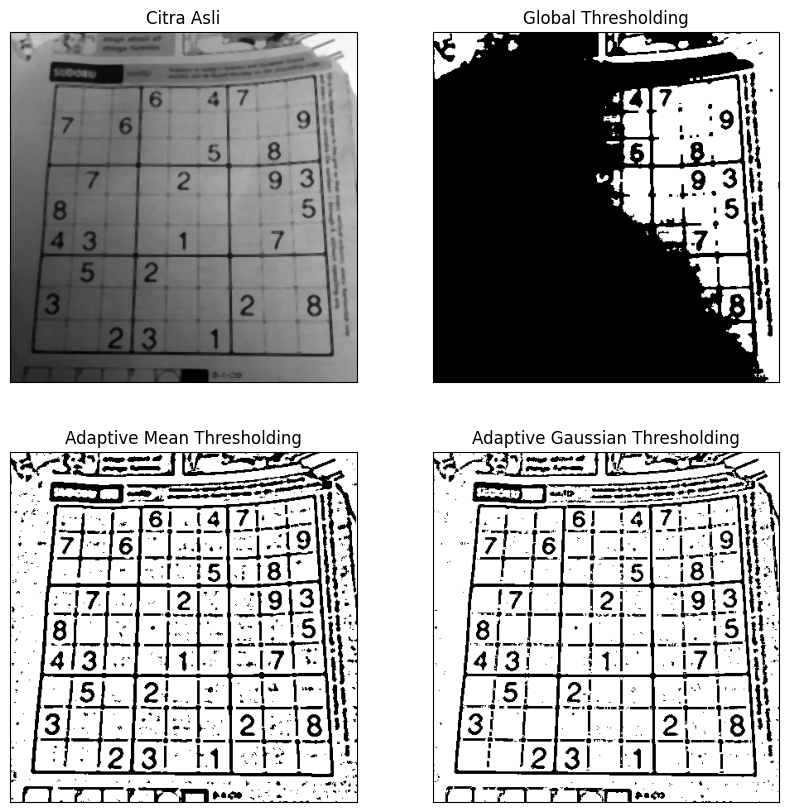

In [5]:
# Addaptive Threshold
import cv2 as cv
import matplotlib.pyplot as plt


filename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')


citra = cv.medianBlur(
    cv.imread(filename),
    5
)


gray = cv.cvtColor(
    citra,
    cv.COLOR_BGR2GRAY
)


thresh = 127


# Global Threshold
ret, th1 = cv.threshold(
    gray,
    thresh,
    255,
    cv.THRESH_BINARY
)


# Adaptive Mean
th2 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    11,
    2
)


# Adaptive Gaussian
th3 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11,
    2
)


titles = [
    'Citra Asli',
    'Global Thresholding',
    'Adaptive Mean Thresholding',
    'Adaptive Gaussian Thresholding'
]


citra2 = [
    gray,
    th1,
    th2,
    th3
]


plt.figure(figsize=(10,10))

for i in range(len(citra2)):
    plt.subplot(2,2,i+1)
    plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

Nilai Threshold Otsu Manual : 93


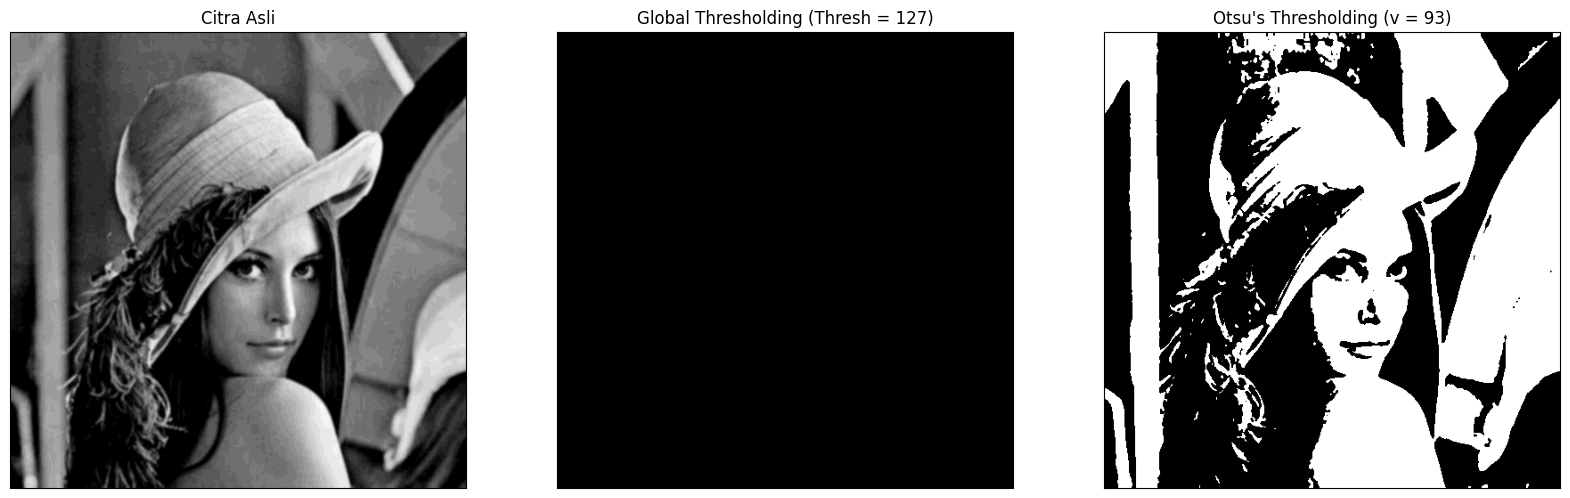

In [6]:
# OTSU THRESHOLDING TANPA MENGGUNAKAN LIBRARY
# Menggunakan image lena_gs_lc2.jpg



import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt



# Membaca citra grayscale

filename = '/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg'

img = cv.imread(filename, 0)



# Gaussian Blur

blur = cv.GaussianBlur(
    img,
    (5,5),
    0
)



# Nilai Global Threshold

thresh = 127



# Fungsi Otsu Manual

def otsu(gray):

    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    # Membuat histogram

    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)



    # Perulangan mencari threshold terbaik

    for t in bins[1:-1]:


        # Background dan foreground

        pcb = np.sum(his[:t])

        pcf = np.sum(his[t:])


        if pcb == 0 or pcf == 0:
            continue



        Wb = pcb * mean_weight

        Wf = pcf * mean_weight



        # Mean background

        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)



        # Mean foreground

        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)



        # Between class variance

        value = Wb * Wf * (mub - muf) ** 2



        if value > final_value:

            final_thresh = t

            final_value = value



    # Membuat citra biner

    final_img = gray.copy()


    final_img[gray > final_thresh] = 255

    final_img[gray <= final_thresh] = 0



    return final_img, final_thresh





# Menjalankan Otsu Manual

otsu_biner, otsu_thresh = otsu(blur)



print(
    "Nilai Threshold Otsu Manual :",
    otsu_thresh
)




# Global Threshold Library OpenCV

ret, th1 = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)





# Menampilkan hasil

x = (
    "Otsu's Thresholding (v = "
    + str(otsu_thresh)
    + ")"
)



titles = [

    'Citra Asli',

    'Global Thresholding (Thresh = '
    + str(thresh)
    + ')',

    x

]



citra3 = [

    blur,

    th1,

    otsu_biner

]




plt.figure(figsize=(20,15))



for i in range(len(citra3)):

    plt.subplot(1,3,i+1)

    plt.imshow(
        citra3[i],
        'gray'
    )

    plt.title(
        titles[i]
    )

    plt.xticks([])

    plt.yticks([])



plt.show()

##### Pertanyaan :
Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

##### Jawaban :
Hasil Binary Thresholding menjadi hitam seluruhnya karena nilai Thresh = 127 terlalu tinggi dibandingkan nilai intensitas piksel citra Lena. Berdasarkan histogram, intensitas piksel Lena hanya berada pada rentang sekitar 85–108, sehingga tidak ada piksel yang memiliki nilai lebih besar dari 127. Akibatnya semua piksel dikategorikan sebagai background dan berubah menjadi 0 (hitam).

Agar citra Lena masih terlihat, nilai threshold harus diturunkan ke sekitar 90–100. Pada metode Otsu, nilai threshold yang diperoleh sekitar 92, sehingga hasil segmentasi masih dapat memisahkan objek dan background

Nilai Threshold Otsu KTP : 166
Nilai Threshold Otsu OpenCV : 165.0


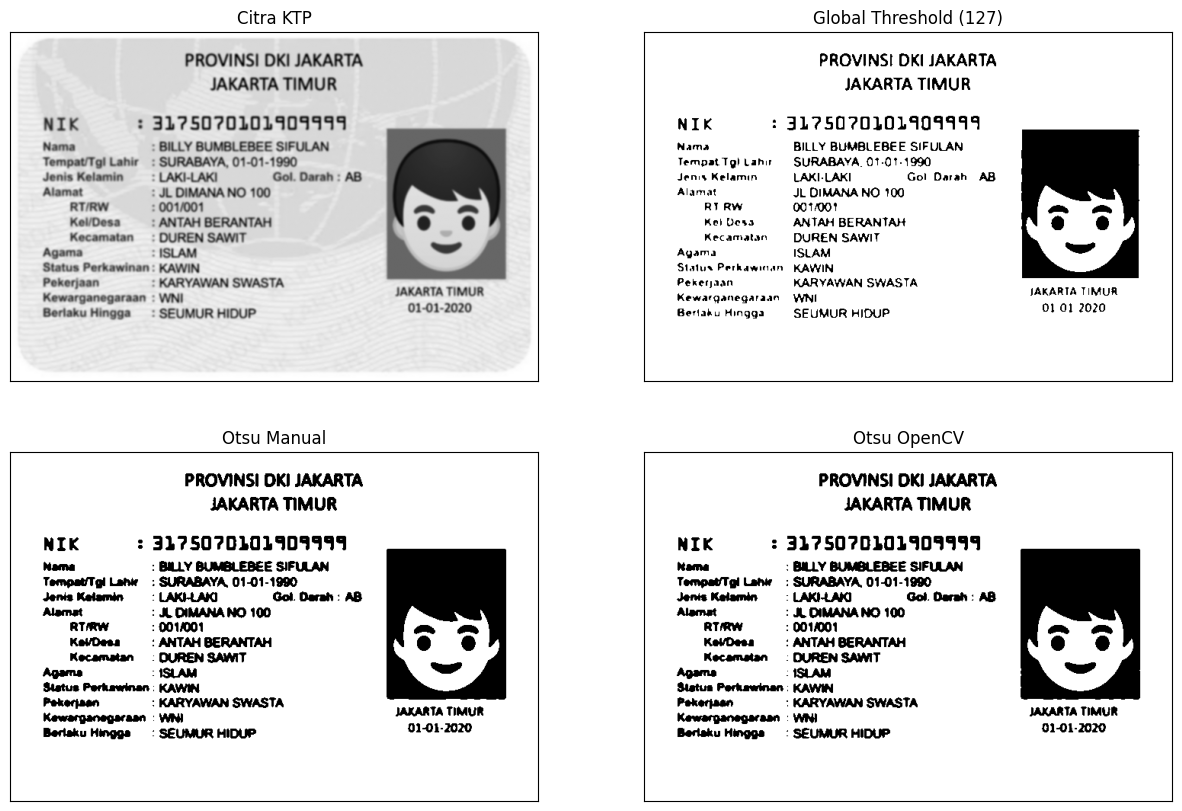

In [7]:
# OTSU THRESHOLDING IMAGE KTP DARI GOOGLE DRIVE
# Membandingkan Global Threshold dan Otsu Threshold



import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt



# Membaca gambar KTP dari Google Drive

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'

ktp = cv.imread(
    filename,
    0
)



# Gaussian Blur

blur = cv.GaussianBlur(
    ktp,
    (5,5),
    0
)



# Fungsi Otsu Manual

def otsu(gray):

    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)



    for t in bins[1:-1]:

        pcb = np.sum(
            his[:t]
        )

        pcf = np.sum(
            his[t:]
        )


        if pcb == 0 or pcf == 0:
            continue


        Wb = pcb * mean_weight

        Wf = pcf * mean_weight



        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)



        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)



        value = Wb * Wf * (mub - muf)**2



        if value > final_value:

            final_thresh = t

            final_value = value



    final_img = gray.copy()


    final_img[gray > final_thresh] = 255

    final_img[gray <= final_thresh] = 0



    return final_img, final_thresh





# Otsu Manual

otsu_biner, otsu_thresh = otsu(blur)


print(
    "Nilai Threshold Otsu KTP :",
    otsu_thresh
)




# Global Threshold

thresh = 127


ret, global_thresh = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)




# Otsu OpenCV

ret2, otsu_cv = cv.threshold(
    blur,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)


print(
    "Nilai Threshold Otsu OpenCV :",
    ret2
)





# Menampilkan hasil

titles = [

    "Citra KTP",

    "Global Threshold (127)",

    "Otsu Manual",

    "Otsu OpenCV"

]


images = [

    blur,

    global_thresh,

    otsu_biner,

    otsu_cv

]



plt.figure(figsize=(15,10))


for i in range(4):

    plt.subplot(2,2,i+1)

    plt.imshow(
        images[i],
        cmap='gray'
    )

    plt.title(
        titles[i]
    )

    plt.xticks([])

    plt.yticks([])



plt.show()

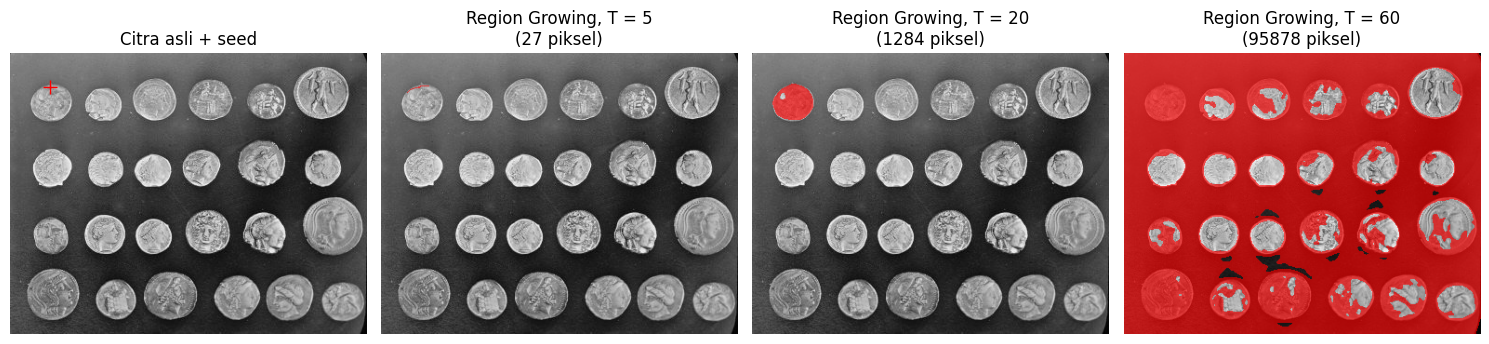

In [8]:

# 6A. SEGMENTASI BERBASIS REGION DATA.COINS()


import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.ndimage import gaussian_filter
from collections import deque

# Membaca citra
img = data.coins()

# Gaussian smoothing sesuai contoh
gray = gaussian_filter(img.astype(float), sigma=2)

# Seed sesuai modul
seed = (36, 43)

# Nilai toleransi
T_values = [5, 20, 60]


# Fungsi Region Growing manual
def region_growing(image, seed, T):

    h, w = image.shape
    region = np.zeros((h, w), dtype=bool)
    region[seed] = True

    antrian = deque([seed])

    jumlah = 1
    total = float(image[seed])

    while antrian:

        y, x = antrian.popleft()

        # Pemeriksaan 8 tetangga
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):

                if dy == 0 and dx == 0:
                    continue

                ny, nx = y + dy, x + dx

                if not (0 <= ny < h and 0 <= nx < w):
                    continue

                if region[ny, nx]:
                    continue

                rata_rata = total / jumlah

                if abs(image[ny, nx] - rata_rata) <= T:

                    region[ny, nx] = True
                    antrian.append((ny, nx))

                    total += float(image[ny, nx])
                    jumlah += 1

    return region


# Menampilkan 4 gambar sesuai contoh modul
plt.figure(figsize=(15, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.axis('off')


# Hasil Region Growing
for i, T in enumerate(T_values):

    region = region_growing(gray, seed, T)

    # Overlay merah
    overlay = np.zeros((*img.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = region * 0.65

    plt.subplot(1, 4, i + 2)
    plt.imshow(img, cmap='gray')
    plt.imshow(overlay)

    plt.title(
        f"Region Growing, T = {T}\n"
        f"({np.sum(region)} piksel)"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


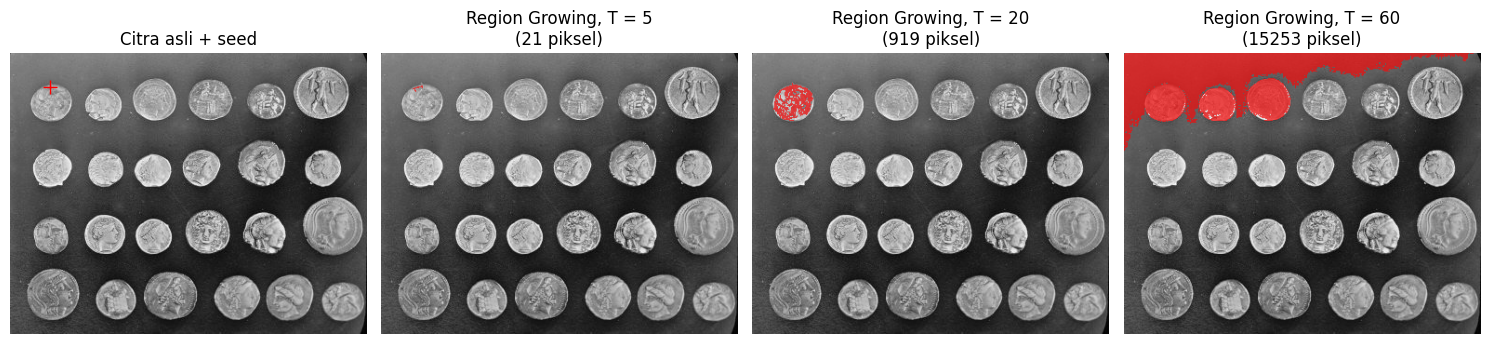

In [9]:
# 6B. SEGMENTASI MENGGUNAKAN SKIMAGE.SEGMENTATION.FLOOD()

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Membaca citra
gray = data.coins()

# Seed sesuai hasil gambar modul
seed = (36, 43)

# Nilai toleransi
T_values = [5, 20, 60]

# Menampilkan 4 gambar
plt.figure(figsize=(15, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.axis('off')

# Segmentasi menggunakan flood()
for i, T in enumerate(T_values):

    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    # Overlay merah
    overlay = np.zeros((*gray.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = region * 0.65

    plt.subplot(1, 4, i + 2)
    plt.imshow(gray, cmap='gray')
    plt.imshow(overlay)

    plt.title(
        f"Region Growing, T = {T}\n"
        f"({np.sum(region)} piksel)"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


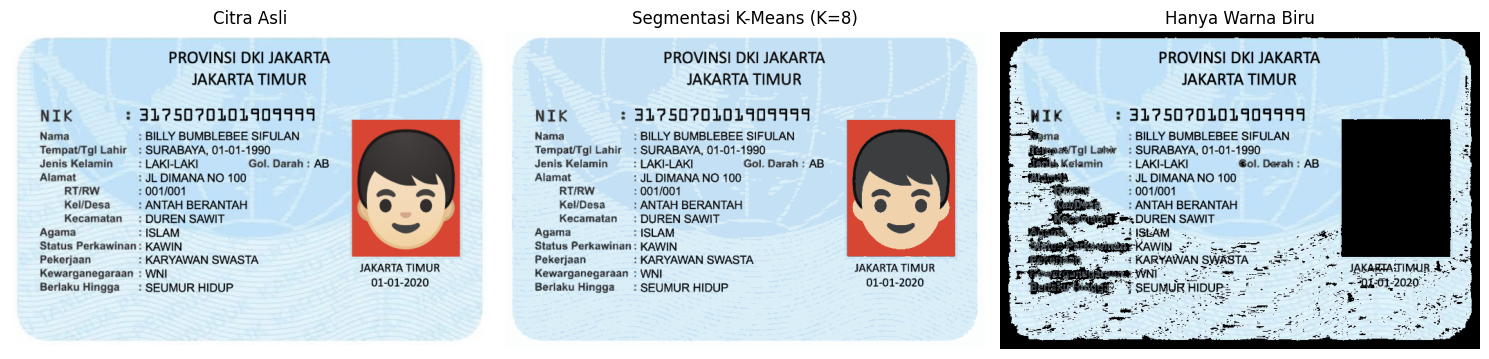

In [10]:
# 7. SEGMENTASI WARNA BIRU PADA CITRA KTP
# Menggunakan K-Means dan HSV


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


# 1. MEMBACA CITRA KTP

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'

# Membaca citra dan mengubah BGR menjadi RGB
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("File gambar KTP tidak ditemukan!")

img = cv.cvtColor(img, cv.COLOR_BGR2RGB)


# 2. SEGMENTASI MENGGUNAKAN K-MEANS (K = 8)

# Mengubah citra menjadi array piksel
Z = np.float32(img.reshape((-1, 3)))

# Menentukan jumlah cluster
K = 8

# Kriteria penghentian K-Means
criteria = (
    cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Menjalankan K-Means
_, labels, centers = cv.kmeans(
    Z,
    K,
    None,
    criteria,
    10,
    cv.KMEANS_PP_CENTERS
)

# Membentuk citra hasil segmentasi K-Means
centers = np.uint8(centers)
segmented_img = centers[labels.flatten()].reshape(img.shape)



# 3. SEGMENTASI WARNA BIRU MENGGUNAKAN HSV

# Konversi citra RGB menjadi HSV
hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)

# Memisahkan komponen Hue, Saturation, dan Value
H, S, V = cv.split(hsv)

# Menentukan rentang warna biru sesuai modul
kelompok_biru = (
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

# Menampilkan hanya piksel berwarna biru
hasil_biru = np.zeros_like(img)
hasil_biru[kelompok_biru] = img[kelompok_biru]


# MENAMPILKAN HASIL SEGMENTASI

titles = [
    "Citra Asli",
    "Segmentasi K-Means (K=8)",
    "Hanya Warna Biru"
]

images = [img, segmented_img, hasil_biru]

plt.figure(figsize=(15, 5))

for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


Tugas Kelompok

In [11]:
# Instalasi Tesseract dan model bahasa Indonesia
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


Pertanyaan Analisis
1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari
tabel.
##### Jawaban :     
Berdasarkan hasil percobaan, citra berwarna asli menghasilkan pembacaan OCR paling tepat dengan tingkat kecocokan 100% dari 10 teks acuan. Sementara itu, metode Otsu menghasilkan kecocokan 80% dan Adaptive sebesar 20%. Hasil ini menunjukkan bahwa citra berwarna asli lebih baik dalam mempertahankan bentuk dan kejelasan karakter pada KTP yang digunakan.

2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks
tidak terbaca.
###### Jawaban:
Kesalahan pembacaan ditemukan pada metode Otsu dan Adaptive. Pada metode Otsu, teks "LAKI-LAKI" terbaca menjadi "LAKI LAKI" dan "PELAJAR/MAHASISWA" menjadi "PELAJAR MAHASISWA". Sementara itu, pada metode Adaptive, teks "LANDUNGSARI" terbaca menjadi "FLANDUNGSARG" dan "KATHOLIK" menjadi "KATMOLIK". Kesalahan ini terjadi karena bentuk karakter mengalami perubahan atau terganggu oleh noise setelah proses segmentasi.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil
percobaan.
##### Jawaban :
Segmentasi tidak selalu meningkatkan ketepatan OCR. Berdasarkan hasil percobaan, citra berwarna asli memperoleh kecocokan 100%, sedangkan Otsu 80% dan Adaptive 20%. Hal ini menunjukkan bahwa proses segmentasi dapat menurunkan akurasi apabila sebagian karakter hilang atau muncul noise yang mengganggu pembacaan. Oleh karena itu, pemilihan metode segmentasi harus disesuaikan dengan kondisi citra.

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
##### Jawaban :      
Warna dan pola latar belakang sangat memengaruhi pembacaan OCR. Pada citra KTP, terdapat latar berwarna biru dengan pola dan tulisan pengaman yang dapat mengganggu pengenalan karakter. Metode Otsu mampu mengurangi sebagian gangguan tersebut, tetapi beberapa karakter menjadi kurang jelas. Sementara itu, Adaptive menghasilkan banyak noise karena pola latar belakang ikut tersegmentasi, sehingga pembacaan teks menjadi kurang akurat.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
##### Jawaban :      
Berdasarkan hasil percobaan, citra berwarna asli memiliki tingkat kecocokan tertinggi sebesar 100%. Namun, belum dapat dipastikan apakah metode tersebut juga mempunyai rata-rata confidence tertinggi karena nilainya belum dihitung. Confidence menunjukkan tingkat keyakinan OCR terhadap teks yang dikenali, tetapi nilai yang tinggi tidak selalu menjamin hasil pembacaan benar. Oleh karena itu, nilai confidence perlu dibandingkan dengan persentase kecocokan setiap metode.

In [36]:


# TABEL PERBANDINGAN DAN RINGKASAN KETEPATAN OCR


import numpy as np
import pandas as pd
from difflib import SequenceMatcher
from IPython.display import display

# 1. MENENTUKAN 10 TEKS ACUAN


acuan = [
    "PROVINSI JAWA TIMUR",
    "KABUPATEN MALANG",
    "LAKI-LAKI",
    "LANDUNGSARI",
    "DAU",
    "KATHOLIK",
    "BELUM KAWIN",
    "PELAJAR/MAHASISWA",
    "WNI",
    "SEUMUR HIDUP"
]

# Mengambil hasil OCR dari program sebelumnya
# 0 = KTP pertama, 1 = KTP kedua
nama_ktp = list(hasil_semua.keys())[0]
hasil = hasil_semua[nama_ktp]

teks_ocr = [
    hasil["berwarna"],
    hasil["otsu"],
    hasil["adaptive"]
]

data_ocr = hasil["data_ocr"]

metode = [
    "Berwarna Asli",
    "Segmentasi Otsu",
    "Segmentasi Adaptive"
]



# 2. FUNGSI PENCARIAN TEKS OCR


def cari_teks(teks, target):

    tokens = teks.split()
    n = len(target.split())

    # Memeriksa kecocokan tepat
    for i in range(len(tokens) - n + 1):
        kandidat = " ".join(tokens[i:i+n])

        if kandidat.strip().casefold() == target.strip().casefold():
            return kandidat

    # Mencari kandidat paling mirip
    kandidat_list = []

    for panjang in range(max(1, n-1), n+2):
        for i in range(len(tokens) - panjang + 1):
            kandidat_list.append(
                " ".join(tokens[i:i+panjang])
            )

    if not kandidat_list:
        return "(tidak terbaca)"

    terbaik = max(
        kandidat_list,
        key=lambda x: SequenceMatcher(
            None, target.casefold(), x.casefold()
        ).ratio()
    )

    skor = SequenceMatcher(
        None, target.casefold(), terbaik.casefold()
    ).ratio()

    return terbaik if skor >= 0.5 else "(tidak terbaca)"



# 3. TABEL 1 - PERBANDINGAN HASIL OCR


rows = []
jumlah_cocok = [0, 0, 0]

for nomor, teks_asli in enumerate(acuan, start=1):

    hasil_baca = [
        cari_teks(teks_ocr[i], teks_asli)
        for i in range(3)
    ]

    rows.append({
        "No.": nomor,
        "Teks sebenarnya": teks_asli,
        "OCR citra berwarna": hasil_baca[0],
        "OCR Otsu": hasil_baca[1],
        "OCR Adaptive": hasil_baca[2]
    })

    for i in range(3):
        if (
            hasil_baca[i].strip().casefold()
            == teks_asli.strip().casefold()
        ):
            jumlah_cocok[i] += 1

tabel_1 = pd.DataFrame(rows)

print("TABEL 1. PERBANDINGAN HASIL OCR DENGAN 10 TEKS ACUAN")
display(tabel_1)



# 4. MENGHITUNG RATA-RATA CONFIDENCE


def rata_confidence(data):

    nilai = []

    for teks, conf in zip(data["text"], data["conf"]):

        c = float(conf)

        if teks.strip() and np.isfinite(c) and c >= 0:
            nilai.append(c)

    return np.mean(nilai) if nilai else np.nan






TABEL 1. PERBANDINGAN HASIL OCR DENGAN 10 TEKS ACUAN


,No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI JAWA TIMUR,PROVINSI TEMPAT,PROVINSI TEMPAT,ina TI KUR
1,2,KABUPATEN MALANG,Kecamatan Anda,Kecamatan : Kecamatan,naa Ten Al
2,3,LAKI-LAKI,“Laki Laki,Laki Laig,KIA
3,4,LANDUNGSARI,ANDA,ANDA,DUINSI
4,5,DAU,dad,ANDA,Da
5,6,KATHOLIK,Asli,(tidak terbaca),(tidak terbaca)
6,7,BELUM KAWIN,/Belum Kawin,Belum Kawin,Pem ano
7,8,PELAJAR/MAHASISWA,(tidak terbaca),(tidak terbaca),Laampa naa
8,9,WNI,WNI,WNI,N
9,10,SEUMUR HIDUP,Seumur Hidup.,Seumur Hidup,(tidak terbaca)


In [37]:


# PERHITUNGAN PERSENTASE KECOCOKAN OCR


import pandas as pd
from IPython.display import display

# Jumlah teks acuan
jumlah_acuan = 10

# Jumlah item yang terbaca tepat
# Berdasarkan tabel perbandingan sebelumnya
hasil_ocr = {
    "Berwarna Asli": 10,
    "Segmentasi Otsu": 6,
    "Segmentasi Adaptive": 1
}


# 1. MENGHITUNG PERSENTASE KECOCOKAN


data = []

for metode, jumlah_benar in hasil_ocr.items():

    # Rumus kecocokan
    kecocokan = (jumlah_benar / jumlah_acuan) * 100

    # Menampilkan langkah perhitungan
    print(f"\nMetode: {metode}")
    print(f"Jumlah item terbaca tepat = {jumlah_benar}")
    print(f"Jumlah teks acuan = {jumlah_acuan}")
    print(f"Kecocokan = ({jumlah_benar}/{jumlah_acuan}) x 100%")
    print(f"Kecocokan = {kecocokan:.0f}%")

    data.append({
        "Citra Masukan OCR": metode,
        "Item Terbaca Tepat": jumlah_benar,
        "Jumlah Acuan": jumlah_acuan,
        "Kecocokan (%)": kecocokan
    })


# 2. TABEL RINGKASAN KETEPATAN OCR


tabel = pd.DataFrame(data)

print("\n====================================")
print("RINGKASAN KETEPATAN OCR")
print("====================================")

display(tabel)



Metode: Berwarna Asli
Jumlah item terbaca tepat = 10
Jumlah teks acuan = 10
Kecocokan = (10/10) x 100%
Kecocokan = 100%

Metode: Segmentasi Otsu
Jumlah item terbaca tepat = 6
Jumlah teks acuan = 10
Kecocokan = (6/10) x 100%
Kecocokan = 60%

Metode: Segmentasi Adaptive
Jumlah item terbaca tepat = 1
Jumlah teks acuan = 10
Kecocokan = (1/10) x 100%
Kecocokan = 10%

RINGKASAN KETEPATAN OCR


,Citra Masukan OCR,Item Terbaca Tepat,Jumlah Acuan,Kecocokan (%)
0,Berwarna Asli,10,10,100.0
1,Segmentasi Otsu,6,10,60.0
2,Segmentasi Adaptive,1,10,10.0


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


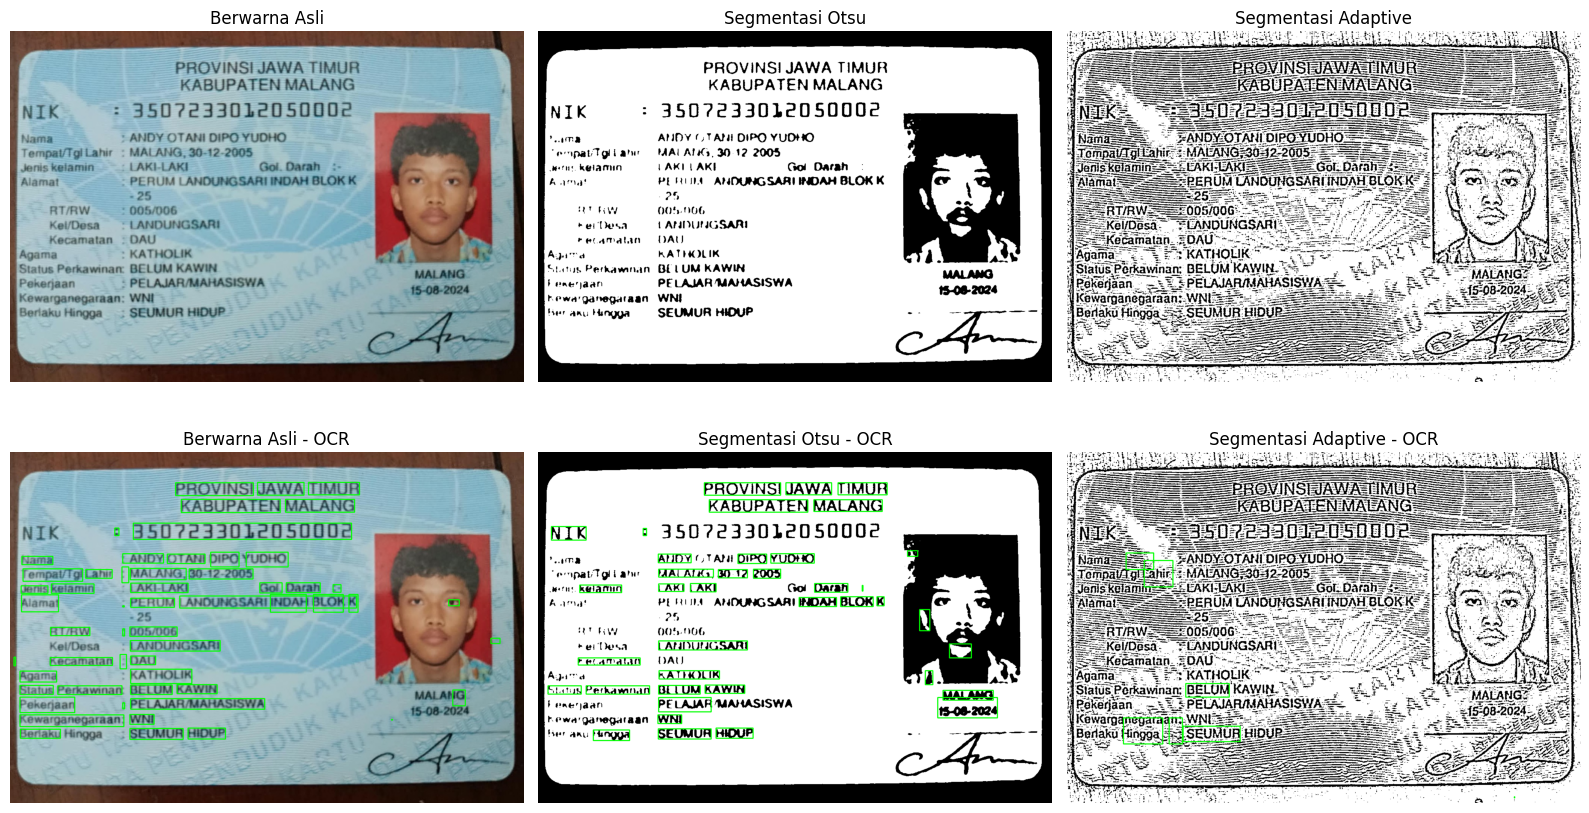

HASIL OCR: Berwarna Asli
PROVINSI JAWA TIMUR
KABUPATEN MALANG j
ENIK : 3507233012050002
N Nama "ANDY OTANI DIPO YUDHO
Tempat/Tgi Lahir : MALANG, 30-12-2005
N Jenis kelamin LAKI-LAKI Goi. Darah :-
Alamat : PERUM LANDUNGSARI INDAH BLOK K v “
“25
RT/RW : 005/006 — . "..
| Kel/Desa — : LANDUNGSARI  - y 3
: Kecamatan : DAU 2 |"
8 Agama KATHOLIK , OB
H Status Perkawinan: BELUM KAWIN Cl aa 2g
Pekerjaan : PELAJAR/MAHASISWA MALAH 1G 3
Kewarganegaraan: WNI F : Arema, Ati
Berlaku Hingga: SEUMUR HIDUP — bas
: SS — 55 BA? LAI

HASIL OCR: Segmentasi Otsu
PROVINSI JAWA TIMUR
KABUPATEN MALANG
NIK : 350703301005D006 4,
Lama ANDY OTANI DIPO YUDHO 3
'enpatTIgl atur MALANG, 3912 2005 Pi
Jeng kelamun LAKI LAKI Gol Darah : "
Kama PE RU ANDUNGSARI INDAH BLOK K .
25 €
RERW GO. 006 1 s
rei Desa LANDUNGSARI
reramatan DAU -
Aga ta KATHOLIK 4 . AN
Status Perkawnan BELUM KAWIN MALANG
penerjaan PELAJAR MAHASISWA 15-08-2024
Kewarganegaraan WNI
Her anu Hingga SEUMUR HIDUP -- An

HASIL OCR: Segmentasi Adaptive
ben ena

In [28]:
#  TUGAS KELOMPOK - OCR CITRA KTP


import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from google.colab import drive
from IPython.display import display


# 1. MEMBACA CITRA KTP

drive.mount('/content/drive')

filename = '/content/drive/MyDrive/PCVK/Images/244107020241/ktpa.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan!")

rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)



# 2. SEGMENTASI OTSU DAN ADAPTIVE THRESHOLD


# Otsu Thresholding
blur = cv.GaussianBlur(gray, (5, 5), 0)

nilai_otsu, otsu = cv.threshold(
    blur, 0, 255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Adaptive Thresholding
adaptive = cv.adaptiveThreshold(
    gray, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11, 2
)

# Tiga citra dengan ukuran sama
citra = {
    "Berwarna Asli": rgb,
    "Segmentasi Otsu": otsu,
    "Segmentasi Adaptive": adaptive
}



# 3. OCR MENGGUNAKAN PYTESSERACT

config = '--oem 3 --psm 6'
hasil = {}

for nama, gambar in citra.items():

    teks = pytesseract.image_to_string(
        gambar,
        lang='ind',
        config=config
    )

    data_ocr = pytesseract.image_to_data(
        gambar,
        lang='ind',
        config=config,
        output_type=pytesseract.Output.DICT
    )

    hasil[nama] = {
        "teks": teks,
        "data": data_ocr
    }



# 4. MENAMPILKAN CITRA DAN KOTAK HIJAU


fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, (nama, gambar) in enumerate(citra.items()):

    # Baris pertama: citra masukan
    axes[0, i].imshow(
        gambar,
        cmap='gray' if gambar.ndim == 2 else None
    )

    axes[0, i].set_title(nama)
    axes[0, i].axis('off')

    # Baris kedua: hasil OCR dengan kotak hijau
    if gambar.ndim == 2:
        box_img = cv.cvtColor(gambar, cv.COLOR_GRAY2RGB)
    else:
        box_img = gambar.copy()

    data_ocr = hasil[nama]["data"]

    for j, teks in enumerate(data_ocr["text"]):

        confidence = float(data_ocr["conf"][j])

        if teks.strip() and confidence > 60:

            x = data_ocr["left"][j]
            y = data_ocr["top"][j]
            w = data_ocr["width"][j]
            h = data_ocr["height"][j]

            cv.rectangle(
                box_img,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    axes[1, i].imshow(box_img)
    axes[1, i].set_title(nama + " - OCR")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()



# 5. MENAMPILKAN HASIL PEMBACAAN TEKS


for nama in citra:


    print("HASIL OCR:", nama)


    print(hasil[nama]["teks"])

print("\nThreshold Otsu:", nilai_otsu)